In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/engage-2-value-from-clicks-to-conversions/sample_submission.csv
/kaggle/input/engage-2-value-from-clicks-to-conversions/train_data.csv
/kaggle/input/engage-2-value-from-clicks-to-conversions/test_data.csv


## Import Libraries

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import lightgbm as lgb
import xgboost as xgb

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [3]:
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)

## Load & Inspect Data

In [4]:
train = pd.read_csv("/kaggle/input/engage-2-value-from-clicks-to-conversions/train_data.csv")
test = pd.read_csv('/kaggle/input/engage-2-value-from-clicks-to-conversions/test_data.csv')

## EXPLORATORY DATA ANALYSIS (EDA)

In [5]:
print("Shape:", train.shape)

Shape: (116023, 52)


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 116023 entries, 0 to 116022
Data columns (total 52 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   trafficSource.isTrueDirect                    42890 non-null   object 
 1   purchaseValue                                 116023 non-null  float64
 2   browser                                       116023 non-null  object 
 3   device.screenResolution                       116023 non-null  object 
 4   trafficSource.adContent                       2963 non-null    object 
 5   trafficSource.keyword                         44162 non-null   object 
 6   screenSize                                    116023 non-null  object 
 7   geoCluster                                    116023 non-null  object 
 8   trafficSource.adwordsClickInfo.slot           4281 non-null    object 
 9   device.mobileDeviceBranding                   11

In [7]:
train.describe()

,purchaseValue,userId,gclIdPresent,sessionNumber,totals.visits,sessionId,trafficSource.adwordsClickInfo.page,pageViews,locationZone,totals.bounces,date,totalHits,sessionStart,new_visits
count,1.160230e+05,116023.000000,116023.000000,116023.000000,116023.0,1.160230e+05,4281.000000,116015.000000,116023.0,47148.0,1.160230e+05,116023.000000,1.160230e+05,80518.0
mean,2.656393e+07,61094.356231,0.037019,2.691311,1.0,1.493429e+09,1.019622,8.412352,8.0,1.0,2.016860e+07,10.607371,1.493429e+09,1.0
std,2.051825e+08,35240.756859,0.188808,10.451613,0.0,1.528798e+07,0.174517,14.344937,0.0,0.0,6.182322e+03,19.629576,1.528798e+07,0.0
min,0.000000e+00,0.000000,0.000000,1.000000,1.0,1.470035e+09,1.000000,1.000000,8.0,1.0,2.016080e+07,1.000000,1.470035e+09,1.0
25%,0.000000e+00,30603.500000,0.000000,1.000000,1.0,1.480066e+09,1.000000,1.000000,8.0,1.0,2.016112e+07,1.000000,1.480066e+09,1.0
50%,0.000000e+00,61014.000000,0.000000,1.000000,1.0,1.491646e+09,1.000000,2.000000,8.0,1.0,2.017041e+07,2.000000,1.491646e+09,1.0
75%,0.000000e+00,91616.500000,0.000000,2.000000,1.0,1.505079e+09,1.000000,10.000000,8.0,1.0,2.017091e+07,12.000000,1.505079e+09,1.0
max,2.312950e+10,122276.000000,1.000000,447.000000,1.0,1.525157e+09,5.000000,469.000000,8.0,1.0,2.018043e+07,500.000000,1.525157e+09,1.0


In [8]:
train.isnull().sum()

trafficSource.isTrueDirect                       73133
purchaseValue                                        0
browser                                              0
device.screenResolution                              0
trafficSource.adContent                         113060
trafficSource.keyword                            71861
screenSize                                           0
geoCluster                                           0
trafficSource.adwordsClickInfo.slot             111742
device.mobileDeviceBranding                          0
device.mobileInputSelector                           0
userId                                               0
trafficSource.campaign                               0
device.mobileDeviceMarketingName                     0
geoNetwork.networkDomain                             0
gclIdPresent                                         0
device.operatingSystemVersion                        0
sessionNumber                                        0
device.fla

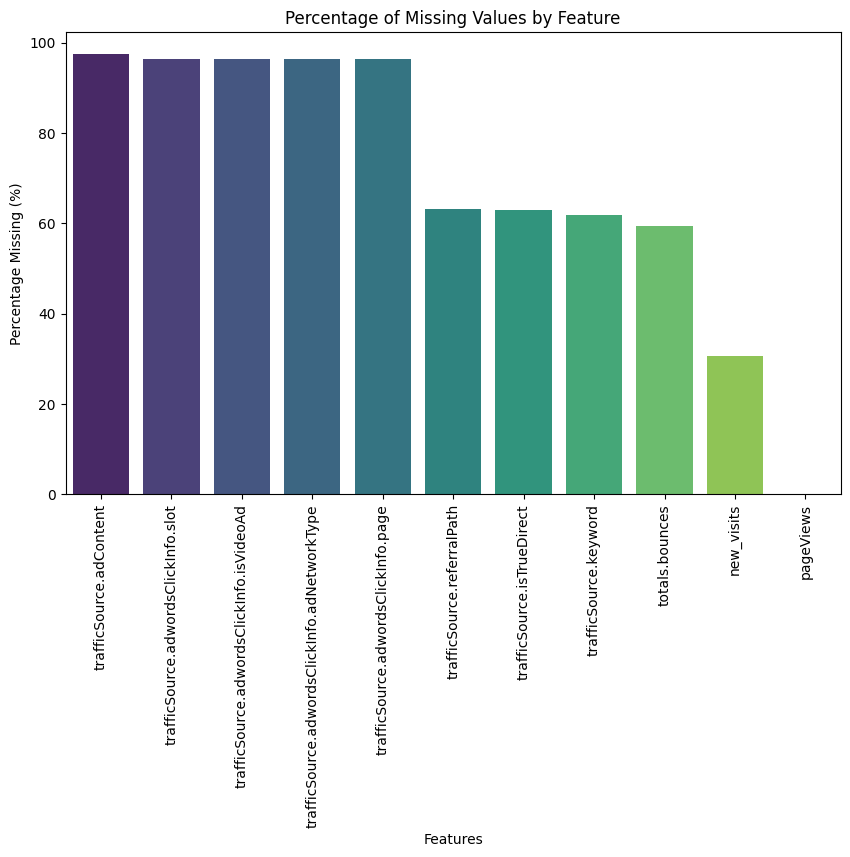

In [9]:
# Visualize the percentage of missing values to identify columns that need imputation or removal.
missing_values = train.isnull().sum() / len(train) * 100
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=missing_values.index, y=missing_values.values, palette='viridis')
plt.title('Percentage of Missing Values by Feature')
plt.xlabel('Features')
plt.ylabel('Percentage Missing (%)')
plt.xticks(rotation=90)
plt.show()

Text(0, 0.5, 'Frequency')

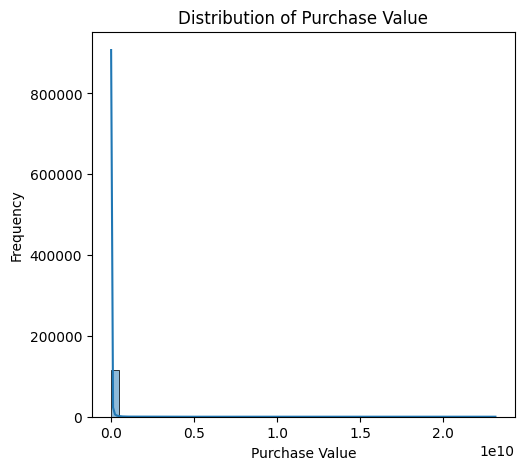

In [10]:
# Target variable: purchaseValue
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train['purchaseValue'], bins=50, kde=True)
plt.title('Distribution of Purchase Value')
plt.xlabel('Purchase Value')
plt.ylabel('Frequency')

The target variable is heavily skewed, with many zero values (sessions without purchases) and a long tail of high-value purchases.

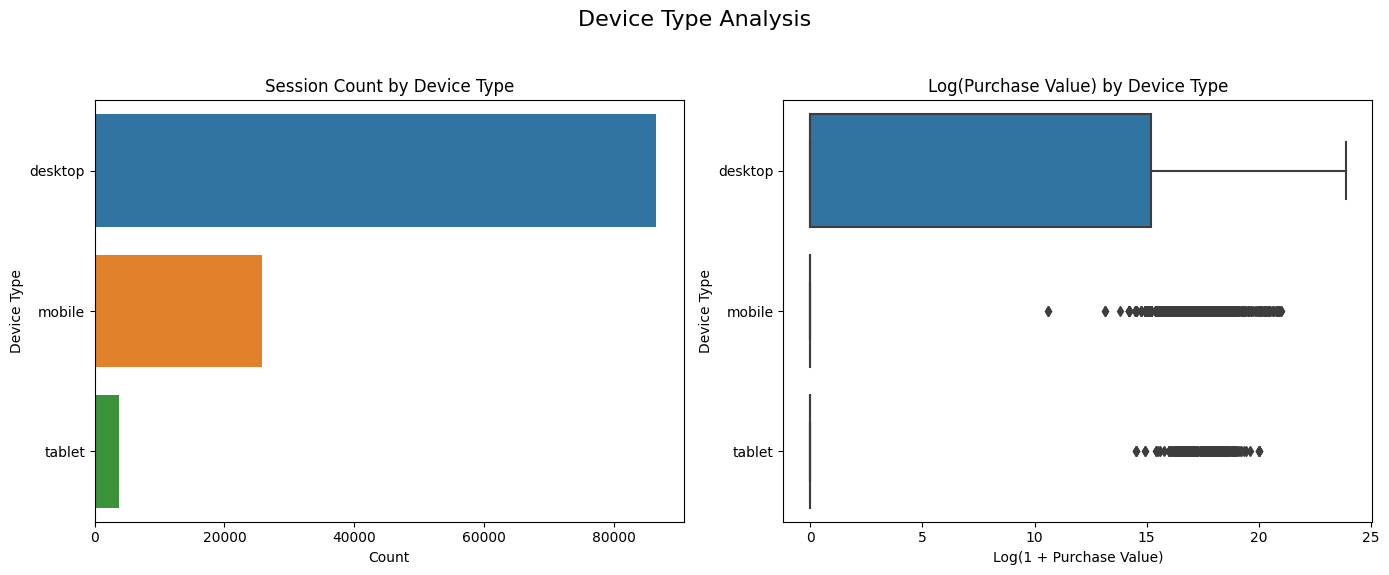

In [11]:
# Device Type vs. Purchase Value

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
sns.countplot(y=train['deviceType'], order=train['deviceType'].value_counts().index)
plt.title('Session Count by Device Type')
plt.xlabel('Count')
plt.ylabel('Device Type')

plt.subplot(1, 2, 2)
sns.boxplot(x=np.log1p(train['purchaseValue']), y=train['deviceType'])
plt.title('Log(Purchase Value) by Device Type')
plt.xlabel('Log(1 + Purchase Value)')
plt.ylabel('Device Type')
plt.suptitle('Device Type Analysis', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


**Desktop users  have higher average purchase value.**

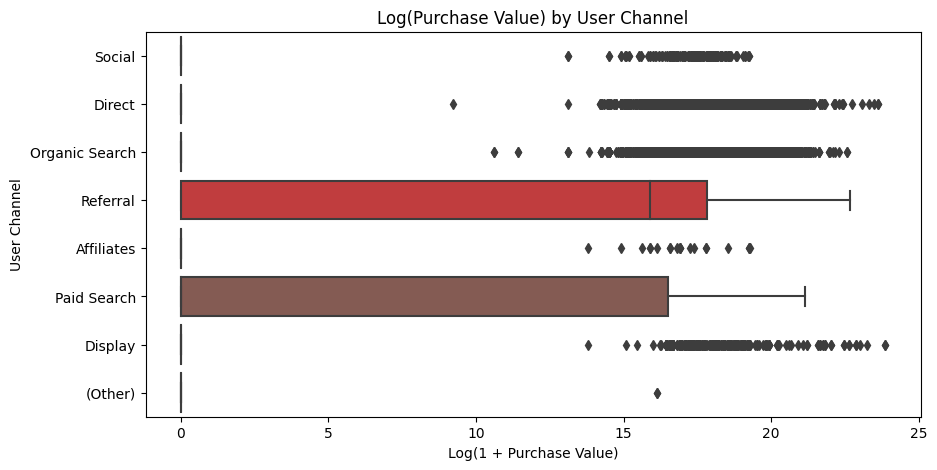

In [12]:
# User Channel vs. Purchase Value
plt.figure(figsize=(10, 5))
sns.boxplot(x=np.log1p(train['purchaseValue']), y=train['userChannel'])
plt.title('Log(Purchase Value) by User Channel')
plt.xlabel('Log(1 + Purchase Value)')
plt.ylabel('User Channel')
plt.show()

**Referral and Direct channels seem to be associated with higher purchase values.**

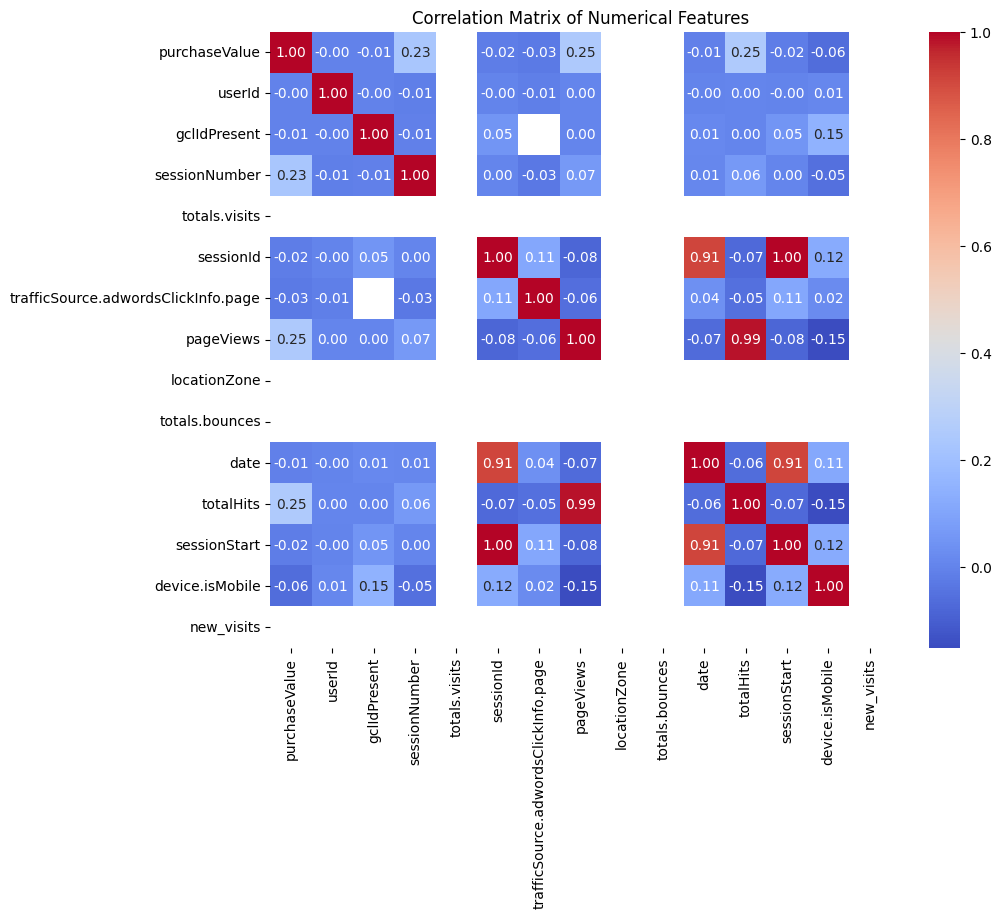

In [13]:
correlation_matrix = train.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Numerical Features")
plt.show()

# Separate features (X) and target (y)

In [14]:
X = train.drop('purchaseValue', axis = 1)
y = train['purchaseValue']

## Split data 

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Preprocessing

In [16]:
# Drop columns with only a single unique value, as they provide no predictive information.

cols_to_drop_single_value = [col for col in X_train.columns if X_train[col].nunique() == 1]

X_train = X_train.drop(columns=cols_to_drop_single_value)
X_test = X_test.drop(columns=cols_to_drop_single_value)

In [17]:
# Replace common placeholder strings with NumPy's NaN for consistent missing value handling.

PLACEHOLDERS = ['not available in demo dataset', '(not set)', '(not provided)', '(none)']
# Process X_train
train_obj_cols = X_train.select_dtypes(include=['object']).columns
X_train[train_obj_cols] = X_train[train_obj_cols].replace(PLACEHOLDERS, np.nan)

# Process X_test
test_obj_cols = X_test.select_dtypes(include=['object']).columns
X_test[test_obj_cols] = X_test[test_obj_cols].replace(PLACEHOLDERS, np.nan)

In [18]:
# Drop high-NaN columns (>= 50%) to reduce noise

nan_pct = X_train.isna().mean() * 100
high_nan_cols = nan_pct[nan_pct >= 50].index.tolist()
X_train.drop(columns=high_nan_cols, inplace=True)
X_test.drop(columns=high_nan_cols, inplace=True)

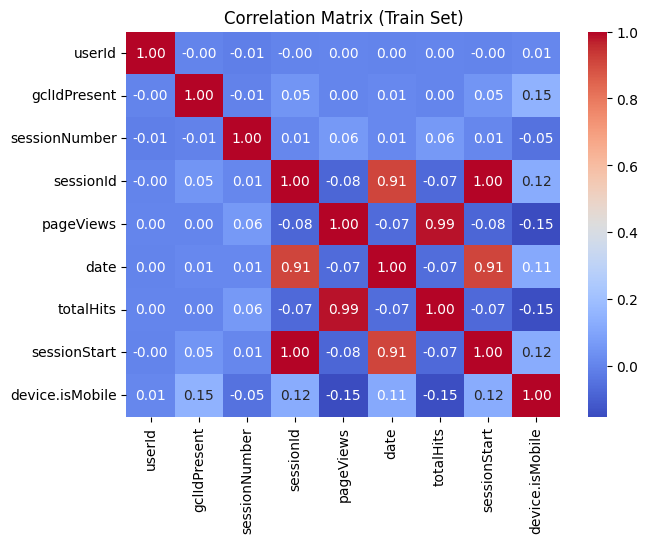

In [19]:
correlation_matrix = X_train.corr(numeric_only=True)
plt.figure(figsize=(7, 5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix (Train Set)")
plt.show()

In [20]:
# Drop sessionId highly correlation with sessionStart

X_train = X_train.drop('sessionId', axis=1)
X_test = X_test.drop('sessionId', axis=1)

## Feature Engineering

Created a custom transformer class to engineer new features. This approach allows us to integrate feature creation seamlessly into our scikit-learn pipeline.

Key new features include:
- User-level Aggregates: Statistics (mean, sum, std) grouped by user ID. This captures user behavior over time.
- Temporal Features: Extracting year, month, hour, etc., from timestamps.
- Interaction Features: Combining categorical features to capture relationships (e.g., channel + device).


In [21]:
from sklearn.base import BaseEstimator, TransformerMixin
import pandas as pd
import numpy as np

class FeatureEngineer(BaseEstimator, TransformerMixin):
    # The __init__ method to prepare for storing learned aggregates
    def __init__(self):
        self.user_aggregates_ = None

    # The fit method now learns user aggregates
    def fit(self, X, y=None):
        """
        Learns user-level statistics (aggregates) from the training data.
        This step is crucial and is only performed on the training set to prevent data leakage.
        """
        
        if 'userId' not in X.columns:
            raise ValueError("Input DataFrame for fitting must contain 'fullVisitorId' column.")
            
        # Define aggregations
        aggregations = {
            'pageViews': ['mean', 'sum', 'std'],
            'totalHits': ['mean', 'sum'],
            'userId': ['count'] # This counts the number of sessions per user
        }
        
        # Calculate aggregations only on the training data
        user_aggregates = X.groupby('userId').agg(aggregations)
        
        # Flatten the MultiIndex column names (e.g., from ('pageViews', 'mean') to 'user_pageViews_mean')
        user_aggregates.columns = ['user_' + '_'.join(col).strip() for col in user_aggregates.columns.values]
        user_aggregates = user_aggregates.rename(columns={'user_id_count': 'user_session_count'})
        
        # Store the learned aggregates as an attribute of the class
        self.user_aggregates_ = user_aggregates
        
        return self

    def transform(self, X):
        """
        Applies all feature transformations.
        """
        # Check if the model has been fitted
        if self.user_aggregates_ is None:
            raise RuntimeError("You must fit the transformer before using transform.")

        Xn = X.copy()

        # Add User-Level Features
        # Merge the learned aggregates. Use a left merge to keep all original rows.
        Xn = pd.merge(Xn, self.user_aggregates_, on='userId', how='left')
        
        # Handle new users in the test set (they will have NaNs after the merge).
        # We fill with 0, as new users have no prior history.
        agg_cols = self.user_aggregates_.columns
        for col in agg_cols:
            if col in Xn.columns:
                Xn[col].fillna(0, inplace=True)

        
        # ---- Temporal Features ----
        if 'date' in Xn.columns:
            Xn['date'] = pd.to_datetime(Xn['date'], format='%Y%m%d')
            Xn['year']      = Xn['date'].dt.year
            Xn['month']     = Xn['date'].dt.month
            Xn['dayofweek'] = Xn['date'].dt.dayofweek
            Xn.drop(columns=['date'], inplace=True)

        # Temporal Features from 'sessionStart'
        if 'sessionStart' in Xn.columns:
            Xn['sessionStart'] = pd.to_datetime(Xn['sessionStart'], unit='s')
            Xn['hour']         = Xn['sessionStart'].dt.hour
            Xn['is_weekend']   = (Xn['sessionStart'].dt.dayofweek >= 5).astype(int)
            
            Xn.drop(columns=['sessionStart'], inplace=True)

        # Engagement & Behavior Features
        if 'pageViews' in Xn.columns and 'totalHits' in Xn.columns:
             Xn['session_depth_ratio'] = Xn['pageViews'] / (Xn['totalHits'] + 1)
        if 'pageViews' in Xn.columns:
             Xn['is_bounce'] = (Xn['pageViews'] <= 1).astype(int)
        if 'sessionNumber' in Xn.columns:
             Xn['is_return_visitor'] = (Xn['sessionNumber'] > 1).astype(int)

        # A composite score to quantify user engagement
        Xn['engagement_score'] = (
            Xn.get('pageViews',0).fillna(0) +
            Xn.get('totalHits',0).fillna(0) +
            2 * Xn.get('sessionNumber',0).fillna(0)
        )
        Xn['engagement_level'] = pd.cut(
            Xn['engagement_score'], bins=[-1, 5, 15, float('inf')], labels=['low','medium','high']
        )
        
        # Geographic Flags
        if 'locationCountry' in Xn.columns:
            high_value_countries = ['United States','Canada','United Kingdom', 'Japan', 'Germany']
            Xn['is_high_value_geo'] = Xn['locationCountry'].isin(high_value_countries).astype(int)

        # Interaction Features
        if 'userChannel' in Xn.columns and 'deviceType' in Xn.columns:
            Xn['channel_device'] = Xn['userChannel'].fillna('') + '_' + Xn['deviceType'].fillna('')
        if 'browser' in Xn.columns and 'os' in Xn.columns:
            Xn['browser_os']     = Xn['browser'].fillna('') + '_' + Xn['os'].fillna('')
        
        # Drop the ID column at the end so the output is purely features
        if 'userId' in Xn.columns:
            Xn = Xn.drop(columns=['userId'])
            
        return Xn

In [22]:
# Apply feature engineering 
feature_engineer = FeatureEngineer()
feature_engineer.fit(X_train)

X_train_engineered = feature_engineer.transform(X_train)
X_test_engineered = feature_engineer.transform(X_test)

In [23]:
numeric_to_scale = [
    'pageViews', 'sessionNumber', 'engagement_score', 'session_depth_ratio',
    'hits_per_session_number', 'views_per_session_number', 
    'hour', 'year', 'month', 'dayofweek', 'user_pageViews_mean',
    'user_pageViews_sum', 'user_pageViews_std', 'user_totalHits_mean',
    'user_totalHits_sum', 'user_session_count'
]

binary_features = [
    'is_bounce', 'is_return_visitor', 'is_high_value_geo',
    'is_weekend', 'is_business_hours' 
]

categorical_features = [
    'deviceType', 'userChannel', 'time_of_day', 'engagement_level',
    'locationCountry', 'browser', 'channel_device', 'browser_os', 'os',
    'geo_channel'
]

In [24]:
# Pipeline for numeric data that needs scaling
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline for binary data (imputation only)
binary_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

# Pipeline for categorical data
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

In [25]:
# Filter lists to ensure columns exist in the DataFrame
numeric_to_scale_cols = [col for col in numeric_to_scale if col in X_train_engineered.columns]
binary_cols = [col for col in binary_features if col in X_train_engineered.columns]
categorical_cols = [col for col in categorical_features if col in X_train_engineered.columns]

preprocessor = ColumnTransformer(transformers=[
    ('num_scaled', numeric_pipeline, numeric_to_scale_cols),
    ('num_binary', binary_pipeline, binary_cols),
    ('cat_onehot', categorical_pipeline, categorical_cols)
], remainder='drop')

In [26]:
preprocessor.fit(X_train_engineered)
X_train_final = preprocessor.transform(X_train_engineered)
X_test_final = preprocessor.transform(X_test_engineered)

## Base model

In [27]:
from sklearn.linear_model import LinearRegression

model_pipeline = Pipeline([
    ('feature_engineering', feature_engineer),
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression()) # The model
])

In [28]:
model_pipeline.fit(X_train, y_train)

Pipeline(steps=[('feature_engineering', FeatureEngineer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num_scaled',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['pageViews', 'sessionNumber',
                                                   'engagement_score',
                                                   'session_depth_ratio',
                                                   'hour', 'year', 'month',
                                                   'dayofweek',
                                                   'user_pageViews_mean',
                                                   'user_pageVie...
                                                   'is_return_visitor',
                                                   'is_high_value_geo',
                                                   'is_weekend']),
                                                 ('cat_onehot',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['deviceType', 'userChannel',
                                                   'engagement_level',
                                                   'locationCountry', 'browser',
                                                   'channel_device',
                                                   'browser_os', 'os'])])),
                ('regressor', LinearRegression())])

In [29]:
# Make predictions on the test set
y_pred = model_pipeline.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R²): {r2:.4f}")

Root Mean Squared Error (RMSE): 198633149.2915
R-squared (R²): 0.1653


In [30]:
models = {
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'LightGBM_Tweedie': lgb.LGBMRegressor(objective='tweedie', random_state=42),
    'XGBoost': xgb.XGBRegressor(random_state=42, n_estimators=100)
}

In [31]:
results = {}
for name, mdl in models.items():
    pipe = Pipeline([
        ('feature_engineering', feature_engineer),
        ('preprocessor', preprocessor),
        ('regressor', mdl)
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='r2')
    results[name] = (scores.mean(), scores.std()*2)
    print(f"{name}: CV R² = {scores.mean():.4f} ± {scores.std()*2:.4f}")

GradientBoosting: CV R² = 0.1884 ± 0.5152
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016633 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2418
[LightGBM] [Info] Number of data points in the train set: 74254, number of used features: 196
[LightGBM] [Info] Start training from score 17.066995
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011424 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2397
[LightGBM] [Info] Number of data points in the train set: 74254, number of used features: 197
[LightGBM] [Info] Start training from score 17.080045
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011406 seconds.
You can set `force_row_wise=true` to r

## Hyperparameter tuning

In [32]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

# Define the pipeline with winning model
lgbm_pipe = Pipeline([
    ('feature_engineering', feature_engineer),
    ('preprocessor', preprocessor),
    ('regressor', lgb.LGBMRegressor(objective='tweedie', random_state=42))
])

# Define the parameter distribution to sample from
param_dist = {
    'regressor__n_estimators': randint(250, 800),
    'regressor__learning_rate': uniform(0.01, 0.2),
    'regressor__num_leaves': randint(30, 60),
    'regressor__max_depth': [-1, 10, 15],
    'regressor__reg_alpha': uniform(0, 1),
    'regressor__reg_lambda': uniform(0, 1),
    'regressor__tweedie_variance_power': uniform(1.1, 0.8) # Search space from 1.1 to 1.9
}

# Set up the randomized search
# n_iter controls how many different parameter combinations to try
random_search = RandomizedSearchCV(
    lgbm_pipe,
    param_distributions=param_dist,
    n_iter=100, # Try 50 different combinations
    cv=5,      # 5-fold cross-validation
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

random_search.fit(X_train, y_train)

print(f"Best R² score found: {random_search.best_score_:.4f}")
print(f"Best parameters found: {random_search.best_params_}")

Fitting 5 folds for each of 100 candidates, totalling 500 fits


/tmp/ipykernel_13/743370463.py:58: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


/tmp/ipykernel_13/743370463.py:58: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.035999 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2418
[LightGBM] [Info] Number of data points in the train set: 74254, number of used features: 196
[LightGBM] [Info] Start training from score 17.066995
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.042871 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2397
[LightGBM] [Info] Number of data points in the train set: 74254, number of used features: 197
[LightGBM] [Info] Start training from score 17.080045
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further sp

/tmp/ipykernel_13/743370463.py:58: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less_equal
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/sklearn/preprocessing/_encoders.py:202: UserWarning: Found unknown categories in columns [3, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/tmp/ipykernel_13/743370463.py:58: FutureWarning: A value is trying to 

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.038860 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2397
[LightGBM] [Info] Number of data points in the train set: 74254, number of used features: 197
[LightGBM] [Info] Start training from score 17.080045
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.221747 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2392
[LightGBM] [Info] Number of data points in the train set: 74255, number of used features: 196
[LightGBM] [Info] Start training from score 17.072852
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.045183 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not e

/tmp/ipykernel_13/743370463.py:58: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less_equal
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/sklearn/preprocessing/_encoders.py:202: UserWarning: Found unknown categories in columns [3, 4, 6, 7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/tmp/ipykernel_13/743370463.py:58: FutureWarning: A value is tryi

... (205 outputs left out)

/tmp/ipykernel_13/743370463.py:58: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less_equal
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/sklearn/preprocessing/_encoders.py:202: UserWarning: Found unknown categories in columns [3, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/tmp/ipykernel_13/743370463.py:58: FutureWarning: A value is trying to 


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No 

/tmp/ipykernel_13/743370463.py:58: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less_equal
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/sklearn/preprocessing/_encoders.py:202: UserWarning: Found unknown categories in columns [3, 4, 5, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/tmp/ipykernel_13/743370463.py:58: FutureWarning: A value is tryi

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.015140 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2440
[LightGBM] [Info] Number of data points in the train set: 92818, number of used features: 202
[LightGBM] [Info] Start training from score 17.076007
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

## Prediction

In [33]:
best_model_pipeline = random_search.best_estimator_
y_pred_final = best_model_pipeline.predict(X_test)

In [34]:
# Calculate final metrics
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))
final_mae = mean_absolute_error(y_test, y_pred_final)
final_r2 = r2_score(y_test, y_pred_final)

# Print a clear, final report
print(f"Final Test Set R-squared (R²): {final_r2:.4f}")
print(f"Final Test Set Root Mean Squared Error (RMSE): {final_rmse:.2f}")
print(f"Final Test Set Mean Absolute Error (MAE): {final_mae:.2f}")

Final Test Set R-squared (R²): 0.4226
Final Test Set Root Mean Squared Error (RMSE): 165204988.19
Final Test Set Mean Absolute Error (MAE): 17054510.20


In [35]:
# Re-train the best model on ALL labeled data (X, y)
best_model_pipeline.fit(X, y)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018577 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2493
[LightGBM] [Info] Number of data points in the train set: 116023, number of used features: 211
[LightGBM] [Info] Start training from score 17.095065
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


Pipeline(steps=[('feature_engineering', FeatureEngineer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num_scaled',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['pageViews', 'sessionNumber',
                                                   'engagement_score',
                                                   'session_depth_ratio',
                                                   'hour', 'year', 'month',
                                                   'dayofweek',
                                                   'user_pageViews_mean',
                                                   'user_pageVie...
                                                  ['deviceType', 'userChannel',
                                                   'engagement_level',
                                                   'locationCountry', 'browser',
                                                   'channel_device',
                                                   'browser_os', 'os'])])),
                ('regressor',
                 LGBMRegressor(learning_rate=0.1985707141115962, max_depth=15,
                               n_estimators=492, num_leaves=51,
                               objective='tweedie', random_state=42,
                               reg_alpha=0.8804678390152577,
                               reg_lambda=0.6243540481337932,
                               tweedie_variance_power=1.3365069486701713))])

In [36]:
# Prepare Test data same as X_train
test_cleaned = test.drop(columns=cols_to_drop_single_value, errors='ignore')
test_obj_cols_final = test_cleaned.select_dtypes(include=['object']).columns
test_cleaned[test_obj_cols_final] = test_cleaned[test_obj_cols_final].replace(PLACEHOLDERS, np.nan)
test_cleaned = test_cleaned.drop(columns=high_nan_cols, errors='ignore')
if 'sessionId' in test_cleaned.columns:
    test_cleaned = test_cleaned.drop('sessionId', axis=1)

In [37]:
# make prediction
final_predictions = best_model_pipeline.predict(test_cleaned)
final_predictions[final_predictions < 0] = 0

In [38]:
submission = pd.DataFrame({"id": range(0,test.shape[0]), "purchaseValue": (final_predictions)}) 
submission.to_csv("submission.csv",index=False)
print(submission)

          id  purchaseValue
0          0   2.448181e+07
1          1   2.355295e+00
2          2   2.986672e-04
3          3   2.356962e+03
4          4   1.065044e+01
...      ...            ...
29001  29001   1.447807e-06
29002  29002   1.695336e+08
29003  29003   5.043308e+07
29004  29004   2.863143e-06
29005  29005   1.922378e-01

[29006 rows x 2 columns]
